In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import xtrack as xt
import xcoll as xc
from pathlib import Path

In [4]:
def combine_lossmaps(study_path, output_name=None, *, result_path=None, plot_path=None, lm_name_pattern='LM_*.json', verbose=True):
    # Combine loss map files and plot
    study_path = Path(study_path).resolve()
    if result_path is None:
        result_path = study_path.parents[2] / 'results'
    result_path = Path(result_path).resolve()
    if plot_path is None:
        plot_path = study_path.parents[2] / 'plots'
    plot_path = Path(plot_path).resolve()
    if output_name is None:
        output_name = ''
    else:
        output_name = output_name + '_'

    files = list(study_path.glob(f'job_*/{lm_name_pattern}'))
    files = [f for f in files if not f.stem.startswith('LM_summary')]
    if len(files) == 0:
        if verbose:
            print('No lossmap files found!')
        return
    if verbose:
        print(f'Found {len(files)} lossmap files')
    lossmap_types = np.unique([f.stem for f in files])
    if verbose:
        print(f"Lossmap types: {', '.join(lossmap_types)}")

    for lm_type in lossmap_types:
        if verbose:
            print(f'  -> Processing lossmap type: {lm_type}')
        lm_files = sorted(study_path.glob(f'job_*/{lm_type}.json'))  # <-- materialise here
        if verbose:
            print(f'     Found {len(lm_files)} files')
        lm = xc.LossMap.from_json(lm_files)
        lm.save_summary(result_path / f'{lm_type}.out')
        lm.to_json(result_path / f'{lm_type}.json')
        lm.plot(show=False, savefig=plot_path / f'{lm_type}.pdf')

In [5]:
study_path = Path('/Users/lisepauwels/mnt/eos/Simulations/CrabCavities/lossmaps_without_crabs/studies/lossmaps_without_crabs/phase_scan/')
result_path = Path('/Users/lisepauwels/mnt/eos/Simulations/CrabCavities/lossmaps_without_crabs/results/jsons/')
plot_path = Path('/Users/lisepauwels/mnt/eos/Simulations/CrabCavities/lossmaps_without_crabs/results/plots/')

combine_lossmaps(study_path, result_path=result_path, plot_path=plot_path, lm_name_pattern='LM_*.json', verbose=True)

Found 5998 lossmap files
Lossmap types: LM_H_0.095, LM_H_0.115, LM_H_0.135, LM_V_0.095, LM_V_0.115, LM_V_0.135
  -> Processing lossmap type: LM_H_0.095
     Found 999 files
Loaded 999 files into loss map.
  -> Processing lossmap type: LM_H_0.115
     Found 1000 files
Loaded 1000 files into loss map.
  -> Processing lossmap type: LM_H_0.135
     Found 1000 files
Loaded 1000 files into loss map.
  -> Processing lossmap type: LM_V_0.095
     Found 1000 files
Loaded 1000 files into loss map.
  -> Processing lossmap type: LM_V_0.115
     Found 999 files
Loaded 999 files into loss map.
  -> Processing lossmap type: LM_V_0.135
     Found 1000 files
Loaded 1000 files into loss map.


# Replotting with right settings

In [15]:
import re
from pathlib import Path

json_dir = Path("jsons/off_momentum_lossmaps")
plot_dir = Path("plots")

number = r"-?\d+(?:\.\d+)?"
pattern = re.compile(
    rf"LM_(?P<lm_type>.+?)__(?P<plane>[^_]+)"
    rf"_collgap_(?P<collgap>{number})"
    rf"_phase_(?P<phase>{number})"
    rf"_crab_plane_(?P<crab_plane>[^_]+)"
    rf"_(?P<errors>with|wo)_errors"
)

for json_file in sorted(json_dir.glob("*.json")):
    match = pattern.fullmatch(json_file.stem)
    if match is None:
        continue

    fields = match.groupdict()

    output_dir = (
        plot_dir
        / f"crab_plane_{fields['crab_plane']}"
        / f"{fields['errors']}_errors"
        / fields["lm_type"]
    )
    output_dir.mkdir(parents=True, exist_ok=True)

    output_name = (
        f"LM_{fields['lm_type']}__{fields['plane']}"
        f"_collgap_{fields['collgap']}"
        f"_phase_{fields['phase']}.pdf"
    )

    lm = xc.LossMap.from_json(json_file)
    lm.plot(show=False, normalise_by_length=False, savefig=output_dir / output_name)

Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file 

# Collimator losses plots

In [ ]:
dico_losses_summary = {}

json_dir = Path("jsons/betatron_lossmaps")
# json_dir = Path("jsons/off_momentum_lossmaps")
#plot_dir = Path("plots")

number = r"-?\d+(?:\.\d+)?"
pattern = re.compile(
    rf"LM_(?P<lm_type>.+?)__(?P<plane>[^_]+)"
    rf"_collgap_(?P<collgap>{number})"
    rf"_phase_(?P<phase>{number})"
    rf"_crab_plane_(?P<crab_plane>[^_]+)"
    rf"_(?P<errors>with|wo)_errors"
)

for json_file in sorted(json_dir.glob("*.json")):
    match = pattern.fullmatch(json_file.stem)
    if match is None:
        continue

    fields = match.groupdict()

    if fields['crab_plane'] not in dico_losses_summary:
        dico_losses_summary[fields['crab_plane']] = {}
    if fields['errors'] not in dico_losses_summary[fields['crab_plane']]:
        dico_losses_summary[fields['crab_plane']][fields['errors']] = {}
    if fields['lm_type'] not in dico_losses_summary[fields['crab_plane']][fields['errors']]:
        dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']] = {}
    if fields['plane'] not in dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']]:
        dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']] = {}
    if fields['collgap'] not in dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']]:
        dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']] = {'phase' : [], 'tcsm' : [], 'tidp' : [], 'aper' : [], 'aper_s' : []}

    dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']]['phase'].append(float(fields['phase']))

    lm = xc.LossMap.from_json(json_file)

    if len(lm.lossmap['collimator']['name']) > 0:
        for ii, nn in enumerate(lm.lossmap['collimator']['name']):
            if 'tcsm' in nn:
                dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']]['tcsm'].append(lm.lossmap['collimator']['n'][ii]/lm.num_initial)
            elif 'tidp' in nn:
                dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']]['tidp'].append(lm.lossmap['collimator']['n'][ii]/lm.num_initial)

        ll_tcsm = len(dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']]['tcsm'])
        ll_tidp = len(dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']]['tidp'])

        if ll_tcsm > ll_tidp:
            dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']]['tidp'].append(0.0)
        elif ll_tidp > ll_tcsm:
            dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']]['tcsm'].append(0.0)

    else:
        dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']]['tcsm'].append(0.0)
        dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']]['tidp'].append(0.0)

    aper, aper_s = np.max(lm.lossmap['aperture']['n']), lm.lossmap['aperture']['s'][np.argmax(lm.lossmap['aperture']['n'])]
    dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']]['aper'].append(aper/lm.num_initial)
    dico_losses_summary[fields['crab_plane']][fields['errors']][fields['lm_type']][fields['plane']][fields['collgap']]['aper_s'].append(aper_s)
    #lm.plot(show=False, normalise_by_length=False, savefig=output_dir / output_name)

Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file into loss map.
Loaded 1 file 

In [79]:
for crab_plane in dico_losses_summary:
    for err_type in dico_losses_summary[crab_plane]:
        for lm_type in dico_losses_summary[crab_plane][err_type]:
            for plane in dico_losses_summary[crab_plane][err_type][lm_type]:
                for collgap in dico_losses_summary[crab_plane][err_type][lm_type][plane]:
                    phase = dico_losses_summary[crab_plane][err_type][lm_type][plane][collgap]['phase']
                    tcsm = dico_losses_summary[crab_plane][err_type][lm_type][plane][collgap]['tcsm']
                    tidp = dico_losses_summary[crab_plane][err_type][lm_type][plane][collgap]['tidp']
                    aper = dico_losses_summary[crab_plane][err_type][lm_type][plane][collgap]['aper']
                    aper_s = dico_losses_summary[crab_plane][err_type][lm_type][plane][collgap]['aper_s']

                    phase, tcsm, tidp, aper, aper_s = map(
                        list,
                        zip(*sorted(zip(phase, tcsm, tidp, aper, aper_s, strict=True), key=lambda row: row[0]))
                    )
                    dico_losses_summary[crab_plane][err_type][lm_type][plane][collgap]['phase'] = phase
                    dico_losses_summary[crab_plane][err_type][lm_type][plane][collgap]['tcsm'] = tcsm
                    dico_losses_summary[crab_plane][err_type][lm_type][plane][collgap]['tidp'] = tidp
                    dico_losses_summary[crab_plane][err_type][lm_type][plane][collgap]['aper'] = aper
                    dico_losses_summary[crab_plane][err_type][lm_type][plane][collgap]['aper_s'] = aper_s

## With errors

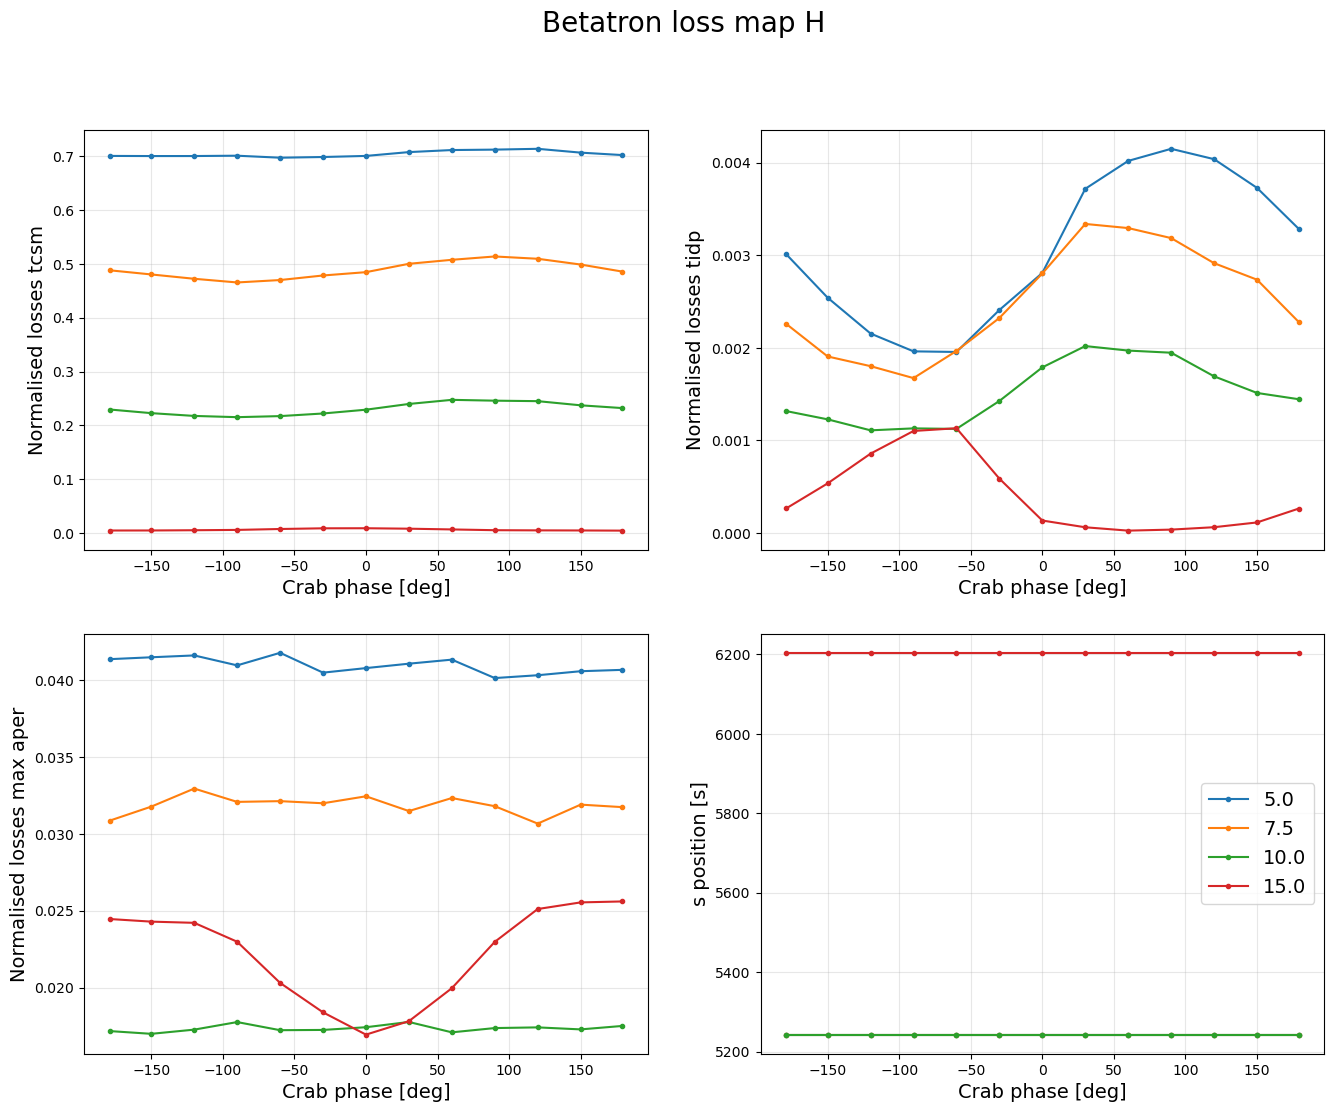

In [106]:
plt.close('all')
fig, ax = plt.subplots(2, 2, figsize=(16,12))

gaps = ['5.0', '7.5', '10.0', '15.0']

for gap in gaps:
    loc = dico_losses_summary['H']['with']['betatron']['H'][gap]
    ax[0,0].plot(loc['phase'], loc['tcsm'], marker='.', label=gap)
    ax[0,1].plot(loc['phase'], loc['tidp'], marker='.', label=gap)
    ax[1,0].plot(loc['phase'], loc['aper'], marker='.', label=gap)
    ax[1,1].plot(loc['phase'], loc['aper_s'], marker='.', label=gap)

ax[0,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,0].set_ylabel('Normalised losses tcsm', fontsize=14)
ax[0,0].grid(alpha=0.3)
ax[0,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,1].set_ylabel('Normalised losses tidp', fontsize=14)
ax[0,1].grid(alpha=0.3)
ax[1,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,0].set_ylabel('Normalised losses max aper', fontsize=14)
ax[1,0].grid(alpha=0.3)
ax[1,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,1].set_ylabel('s position [s]', fontsize=14)
ax[1,1].grid(alpha=0.3)
ax[1,1].legend(fontsize=14)

fig.suptitle('Betatron loss map H', fontsize=20)
plt.show()

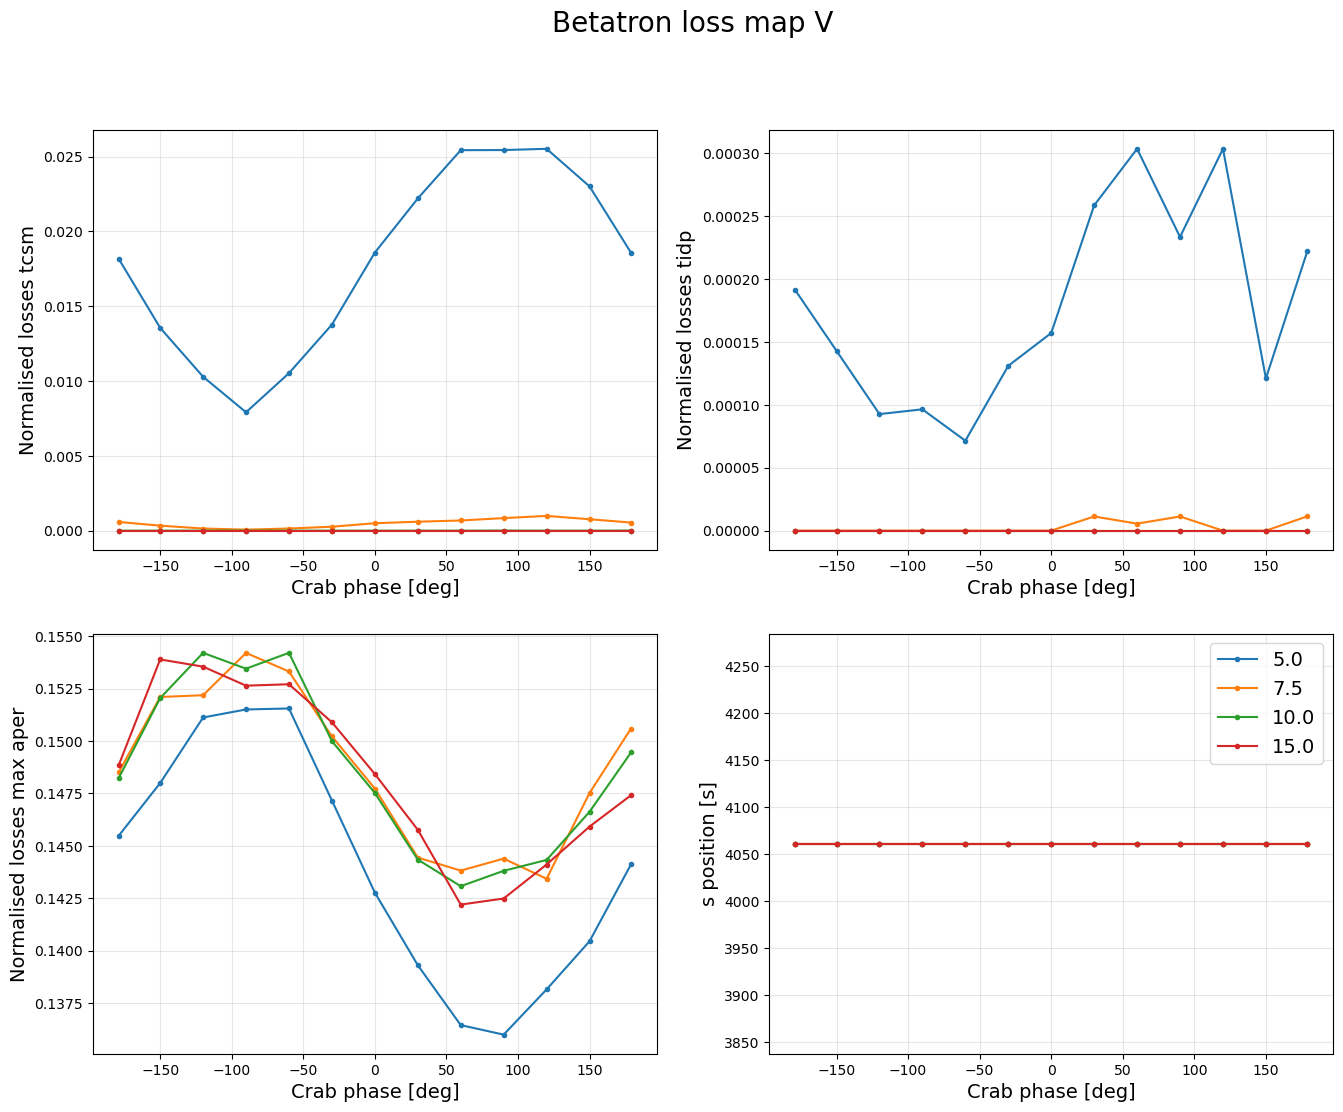

In [107]:
plt.close('all')
fig, ax = plt.subplots(2, 2, figsize=(16,12))

gaps = ['5.0', '7.5', '10.0', '15.0']

for gap in gaps:
    loc = dico_losses_summary['H']['with']['betatron']['V'][gap]
    ax[0,0].plot(loc['phase'], loc['tcsm'], marker='.', label=gap)
    ax[0,1].plot(loc['phase'], loc['tidp'], marker='.', label=gap)
    ax[1,0].plot(loc['phase'], loc['aper'], marker='.', label=gap)
    ax[1,1].plot(loc['phase'], loc['aper_s'], marker='.', label=gap)

ax[0,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,0].set_ylabel('Normalised losses tcsm', fontsize=14)
ax[0,0].grid(alpha=0.3)
ax[0,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,1].set_ylabel('Normalised losses tidp', fontsize=14)
ax[0,1].grid(alpha=0.3)
ax[1,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,0].set_ylabel('Normalised losses max aper', fontsize=14)
ax[1,0].grid(alpha=0.3)
ax[1,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,1].set_ylabel('s position [s]', fontsize=14)
ax[1,1].grid(alpha=0.3)
ax[1,1].legend(fontsize=14)
fig.suptitle('Betatron loss map V', fontsize=20)
plt.show()

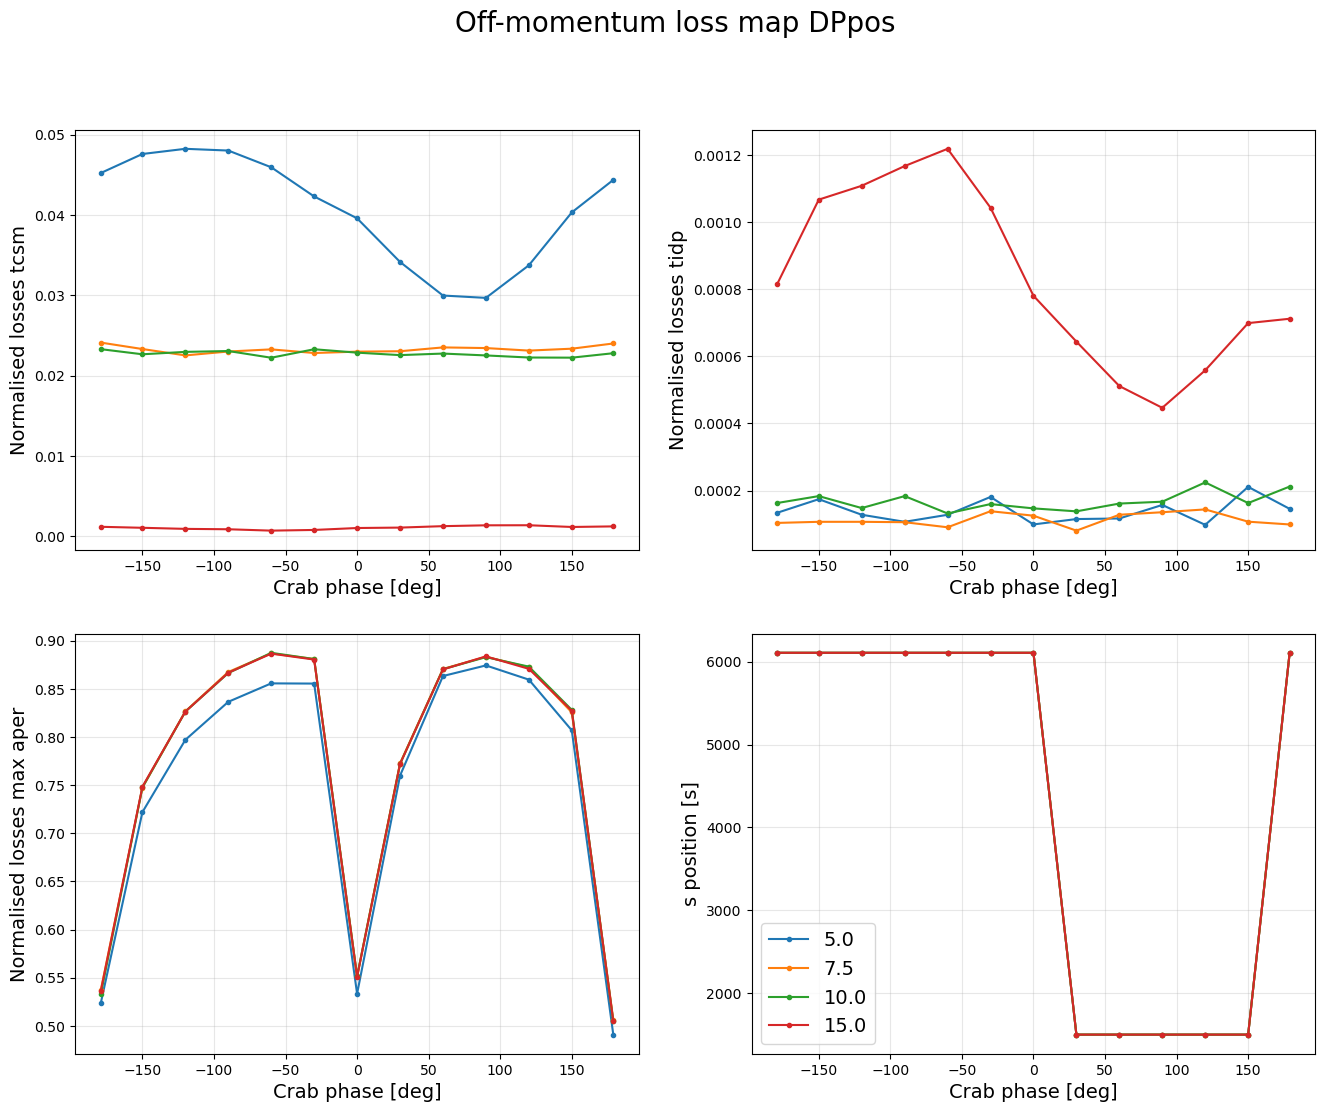

In [108]:
plt.close('all')
fig, ax = plt.subplots(2, 2, figsize=(16,12))

gaps = ['5.0', '7.5', '10.0', '15.0']

for gap in gaps:
    loc = dico_losses_summary['H']['with']['off_momentum']['DPpos'][gap]
    ax[0,0].plot(loc['phase'], loc['tcsm'], marker='.', label=gap)
    ax[0,1].plot(loc['phase'], loc['tidp'], marker='.', label=gap)
    ax[1,0].plot(loc['phase'], loc['aper'], marker='.', label=gap)
    ax[1,1].plot(loc['phase'], loc['aper_s'], marker='.', label=gap)

ax[0,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,0].set_ylabel('Normalised losses tcsm', fontsize=14)
ax[0,0].grid(alpha=0.3)
ax[0,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,1].set_ylabel('Normalised losses tidp', fontsize=14)
ax[0,1].grid(alpha=0.3)
ax[1,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,0].set_ylabel('Normalised losses max aper', fontsize=14)
ax[1,0].grid(alpha=0.3)
ax[1,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,1].set_ylabel('s position [s]', fontsize=14)
ax[1,1].grid(alpha=0.3)
ax[1,1].legend(fontsize=14)

fig.suptitle('Off-momentum loss map DPpos', fontsize=20)
plt.show()

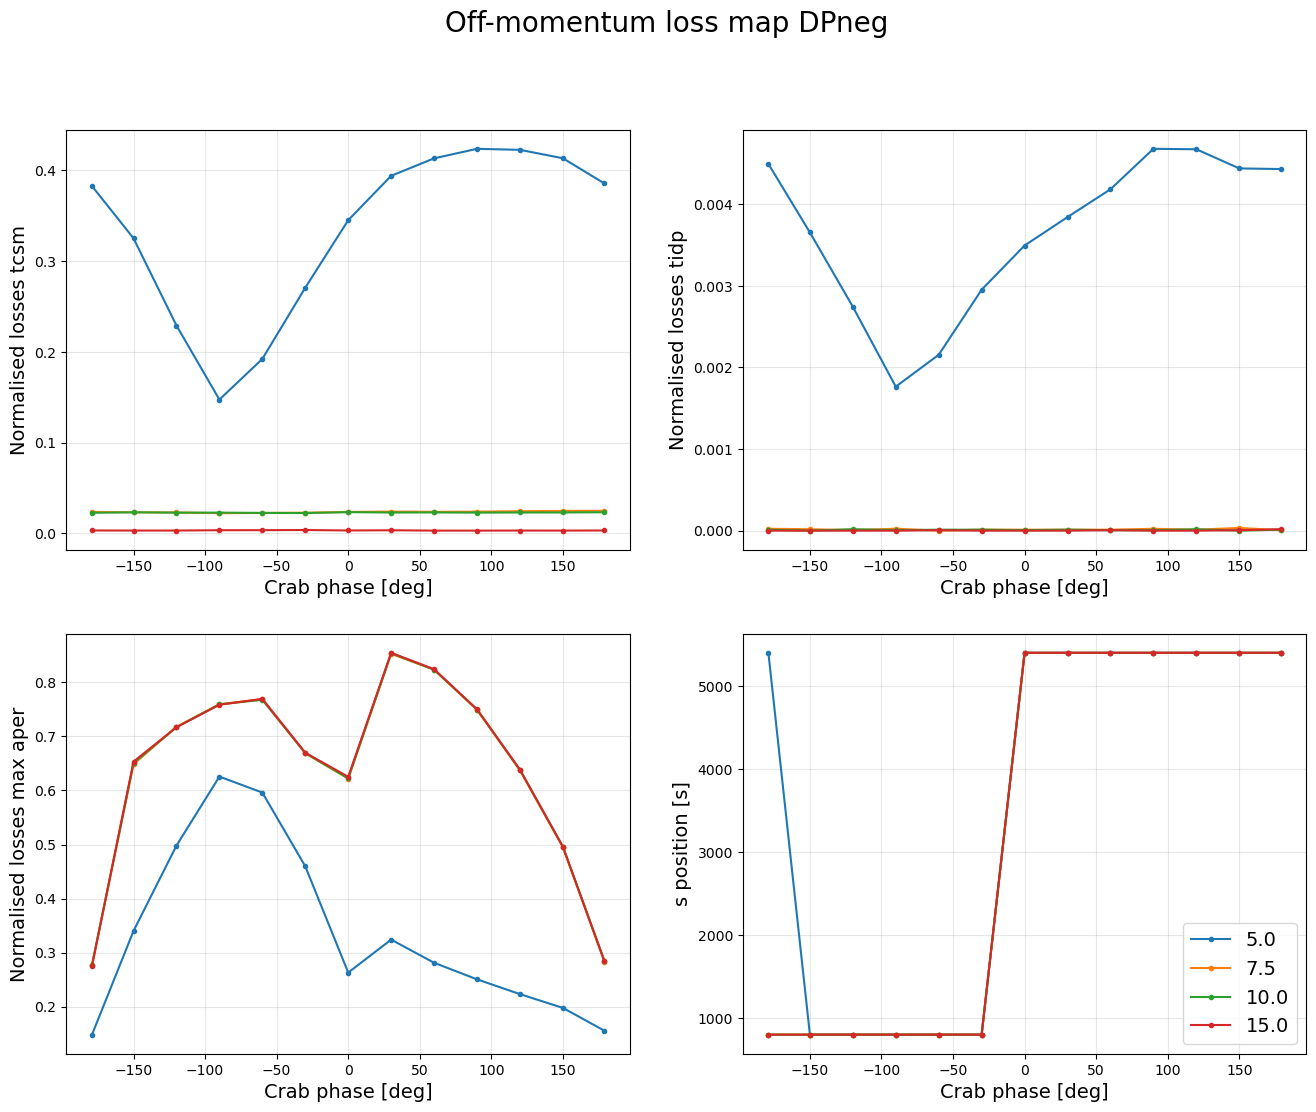

In [109]:
plt.close('all')
fig, ax = plt.subplots(2, 2, figsize=(16,12))

gaps = ['5.0', '7.5', '10.0', '15.0']

for gap in gaps:
    loc = dico_losses_summary['H']['with']['off_momentum']['DPneg'][gap]
    ax[0,0].plot(loc['phase'], loc['tcsm'], marker='.', label=gap)
    ax[0,1].plot(loc['phase'], loc['tidp'], marker='.', label=gap)
    ax[1,0].plot(loc['phase'], loc['aper'], marker='.', label=gap)
    ax[1,1].plot(loc['phase'], loc['aper_s'], marker='.', label=gap)

ax[0,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,0].set_ylabel('Normalised losses tcsm', fontsize=14)
ax[0,0].grid(alpha=0.3)
ax[0,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,1].set_ylabel('Normalised losses tidp', fontsize=14)
ax[0,1].grid(alpha=0.3)
ax[1,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,0].set_ylabel('Normalised losses max aper', fontsize=14)
ax[1,0].grid(alpha=0.3)
ax[1,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,1].set_ylabel('s position [s]', fontsize=14)
ax[1,1].grid(alpha=0.3)
ax[1,1].legend(fontsize=14)

fig.suptitle('Off-momentum loss map DPneg', fontsize=20)
plt.show()

In [104]:
# plt.close('all')
# fig, ax = plt.subplots(figsize=(8,6))

# gaps = ['5.0', '7.5', '10.0', '15.0']

# for gap in gaps:
#     loc = dico_losses_summary['H']['with']['betatron']['H'][gap]
#     ax.plot(loc['phase'], loc['tcsm'], marker='.', label=gap)

# ax.set_xlabel('Crab phase [deg]', fontsize=14)
# ax.set_ylabel('Normalised losses', fontsize=14)
# ax.grid(alpha=0.3)
# ax.legend(fontsize=14)
# ax.set_title('TCSM variation', fontsize=17)
# plt.show()

## Without errors

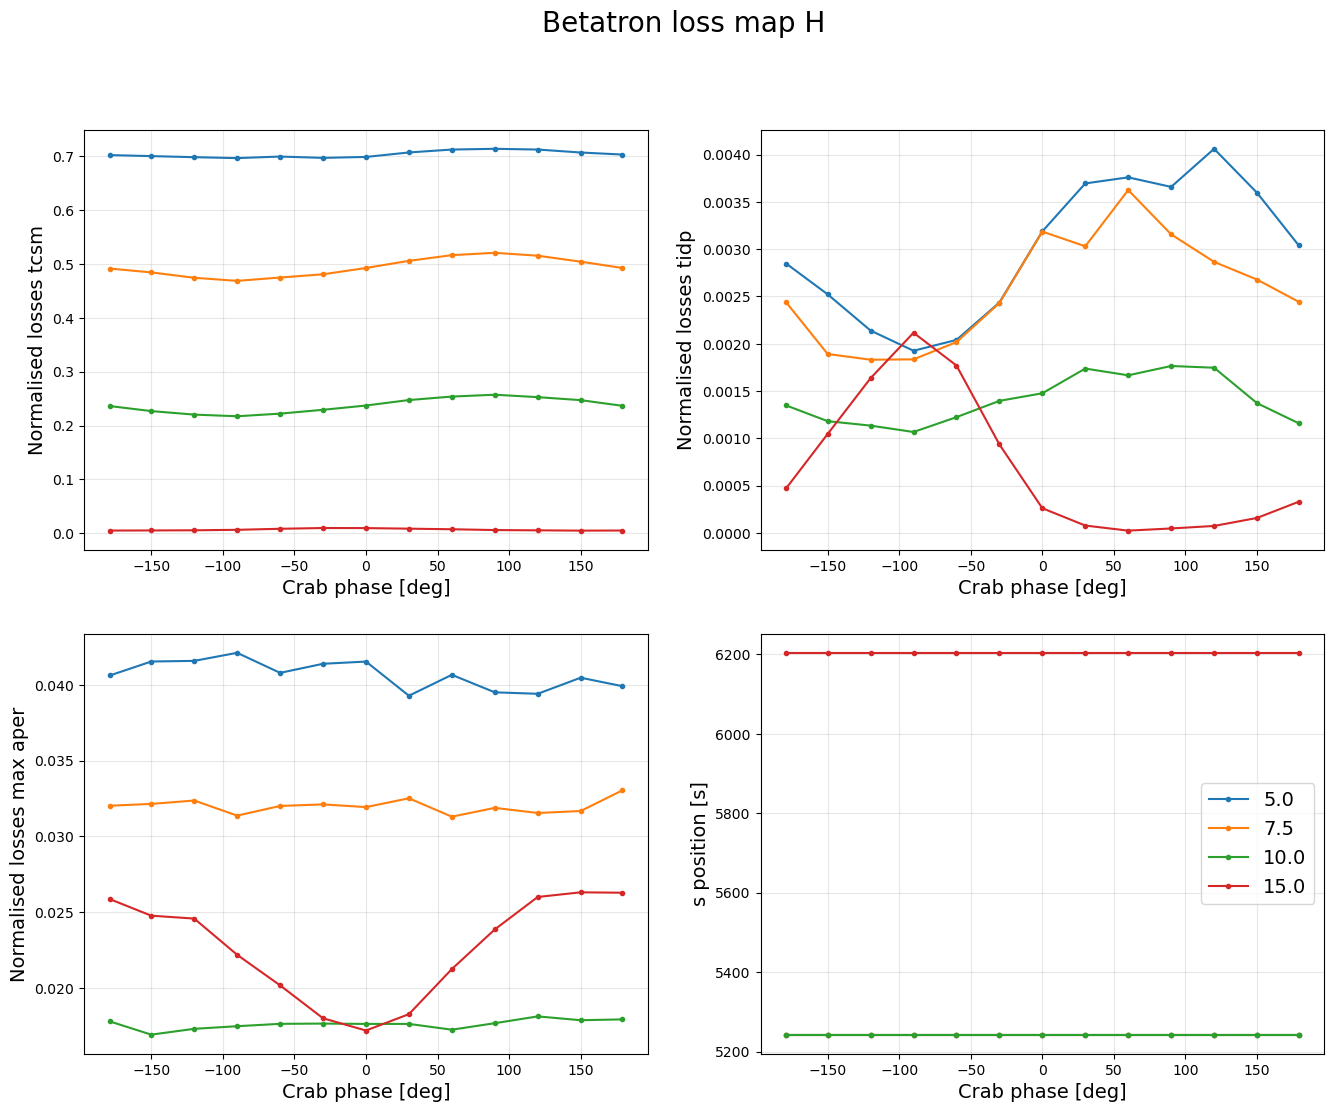

In [110]:
plt.close('all')
fig, ax = plt.subplots(2, 2, figsize=(16,12))

gaps = ['5.0', '7.5', '10.0', '15.0']

for gap in gaps:
    loc = dico_losses_summary['H']['wo']['betatron']['H'][gap]
    ax[0,0].plot(loc['phase'], loc['tcsm'], marker='.', label=gap)
    ax[0,1].plot(loc['phase'], loc['tidp'], marker='.', label=gap)
    ax[1,0].plot(loc['phase'], loc['aper'], marker='.', label=gap)
    ax[1,1].plot(loc['phase'], loc['aper_s'], marker='.', label=gap)

ax[0,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,0].set_ylabel('Normalised losses tcsm', fontsize=14)
ax[0,0].grid(alpha=0.3)
ax[0,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,1].set_ylabel('Normalised losses tidp', fontsize=14)
ax[0,1].grid(alpha=0.3)
ax[1,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,0].set_ylabel('Normalised losses max aper', fontsize=14)
ax[1,0].grid(alpha=0.3)
ax[1,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,1].set_ylabel('s position [s]', fontsize=14)
ax[1,1].grid(alpha=0.3)
ax[1,1].legend(fontsize=14)

fig.suptitle('Betatron loss map H', fontsize=20)
plt.show()

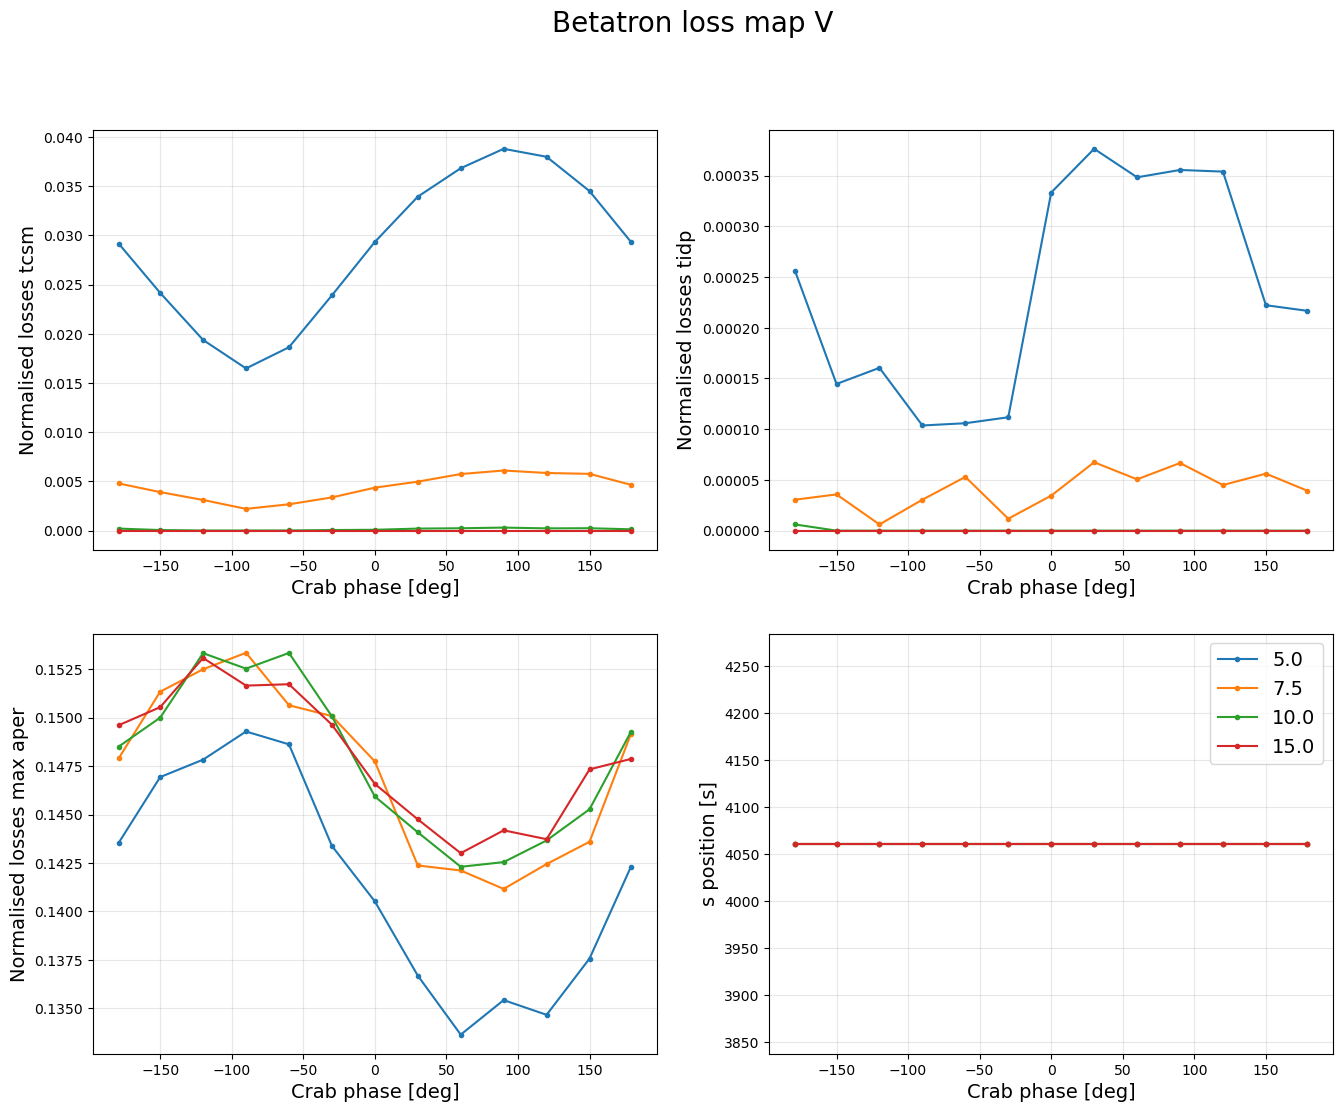

In [111]:
plt.close('all')
fig, ax = plt.subplots(2, 2, figsize=(16,12))

gaps = ['5.0', '7.5', '10.0', '15.0']

for gap in gaps:
    loc = dico_losses_summary['H']['wo']['betatron']['V'][gap]
    ax[0,0].plot(loc['phase'], loc['tcsm'], marker='.', label=gap)
    ax[0,1].plot(loc['phase'], loc['tidp'], marker='.', label=gap)
    ax[1,0].plot(loc['phase'], loc['aper'], marker='.', label=gap)
    ax[1,1].plot(loc['phase'], loc['aper_s'], marker='.', label=gap)

ax[0,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,0].set_ylabel('Normalised losses tcsm', fontsize=14)
ax[0,0].grid(alpha=0.3)
ax[0,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,1].set_ylabel('Normalised losses tidp', fontsize=14)
ax[0,1].grid(alpha=0.3)
ax[1,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,0].set_ylabel('Normalised losses max aper', fontsize=14)
ax[1,0].grid(alpha=0.3)
ax[1,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,1].set_ylabel('s position [s]', fontsize=14)
ax[1,1].grid(alpha=0.3)
ax[1,1].legend(fontsize=14)
fig.suptitle('Betatron loss map V', fontsize=20)
plt.show()

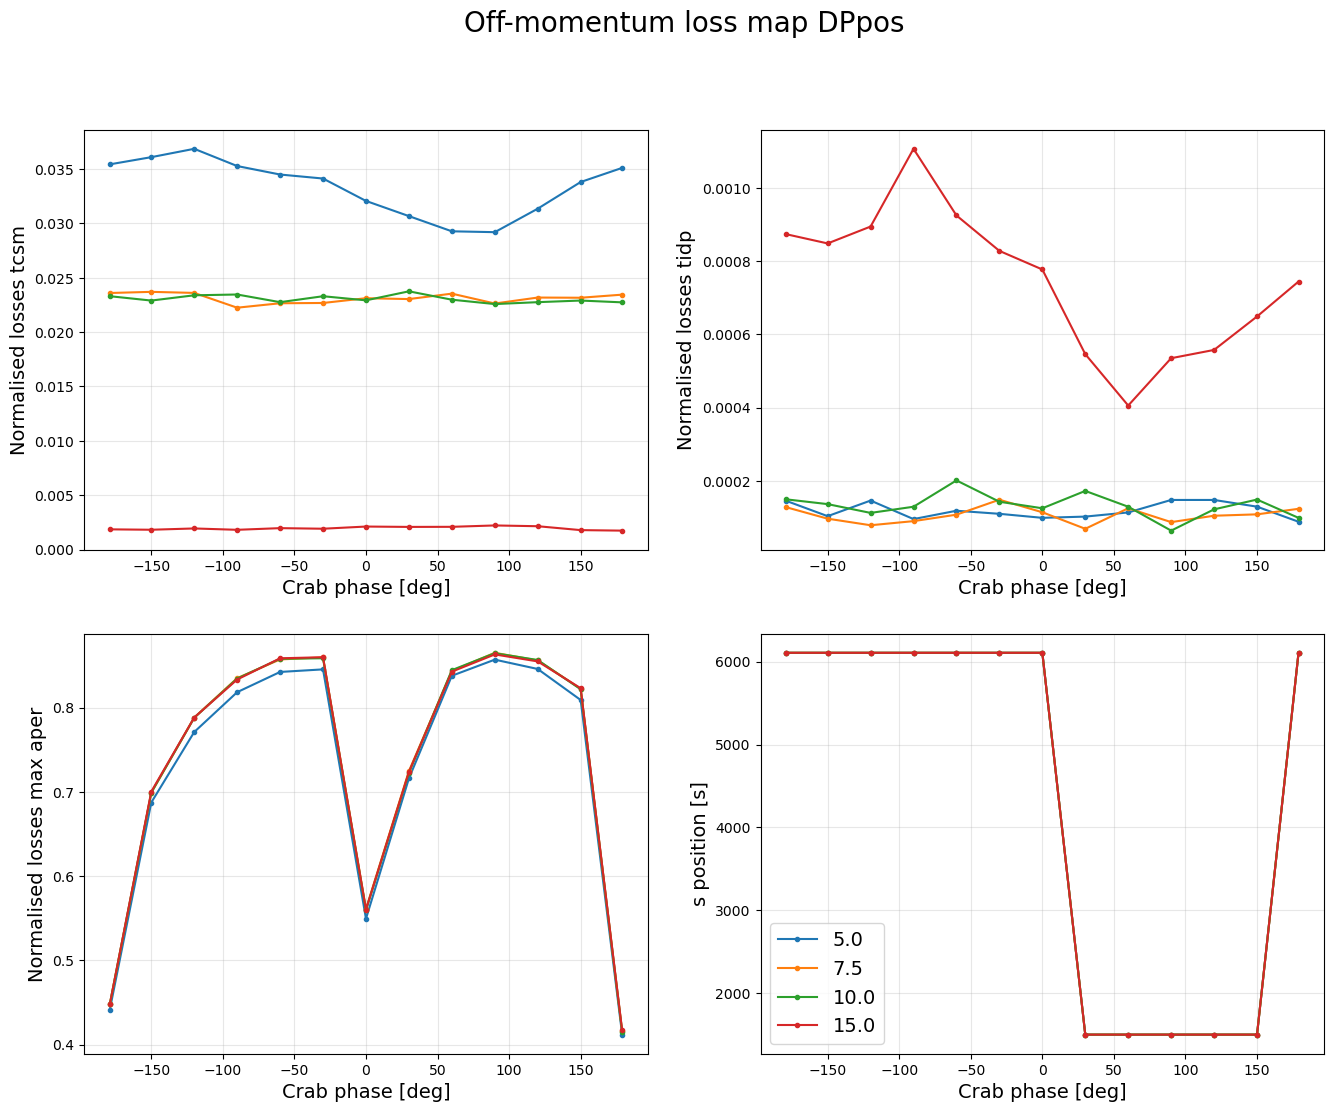

In [112]:
plt.close('all')
fig, ax = plt.subplots(2, 2, figsize=(16,12))

gaps = ['5.0', '7.5', '10.0', '15.0']

for gap in gaps:
    loc = dico_losses_summary['H']['wo']['off_momentum']['DPpos'][gap]
    ax[0,0].plot(loc['phase'], loc['tcsm'], marker='.', label=gap)
    ax[0,1].plot(loc['phase'], loc['tidp'], marker='.', label=gap)
    ax[1,0].plot(loc['phase'], loc['aper'], marker='.', label=gap)
    ax[1,1].plot(loc['phase'], loc['aper_s'], marker='.', label=gap)

ax[0,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,0].set_ylabel('Normalised losses tcsm', fontsize=14)
ax[0,0].grid(alpha=0.3)
ax[0,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,1].set_ylabel('Normalised losses tidp', fontsize=14)
ax[0,1].grid(alpha=0.3)
ax[1,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,0].set_ylabel('Normalised losses max aper', fontsize=14)
ax[1,0].grid(alpha=0.3)
ax[1,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,1].set_ylabel('s position [s]', fontsize=14)
ax[1,1].grid(alpha=0.3)
ax[1,1].legend(fontsize=14)

fig.suptitle('Off-momentum loss map DPpos', fontsize=20)
plt.show()

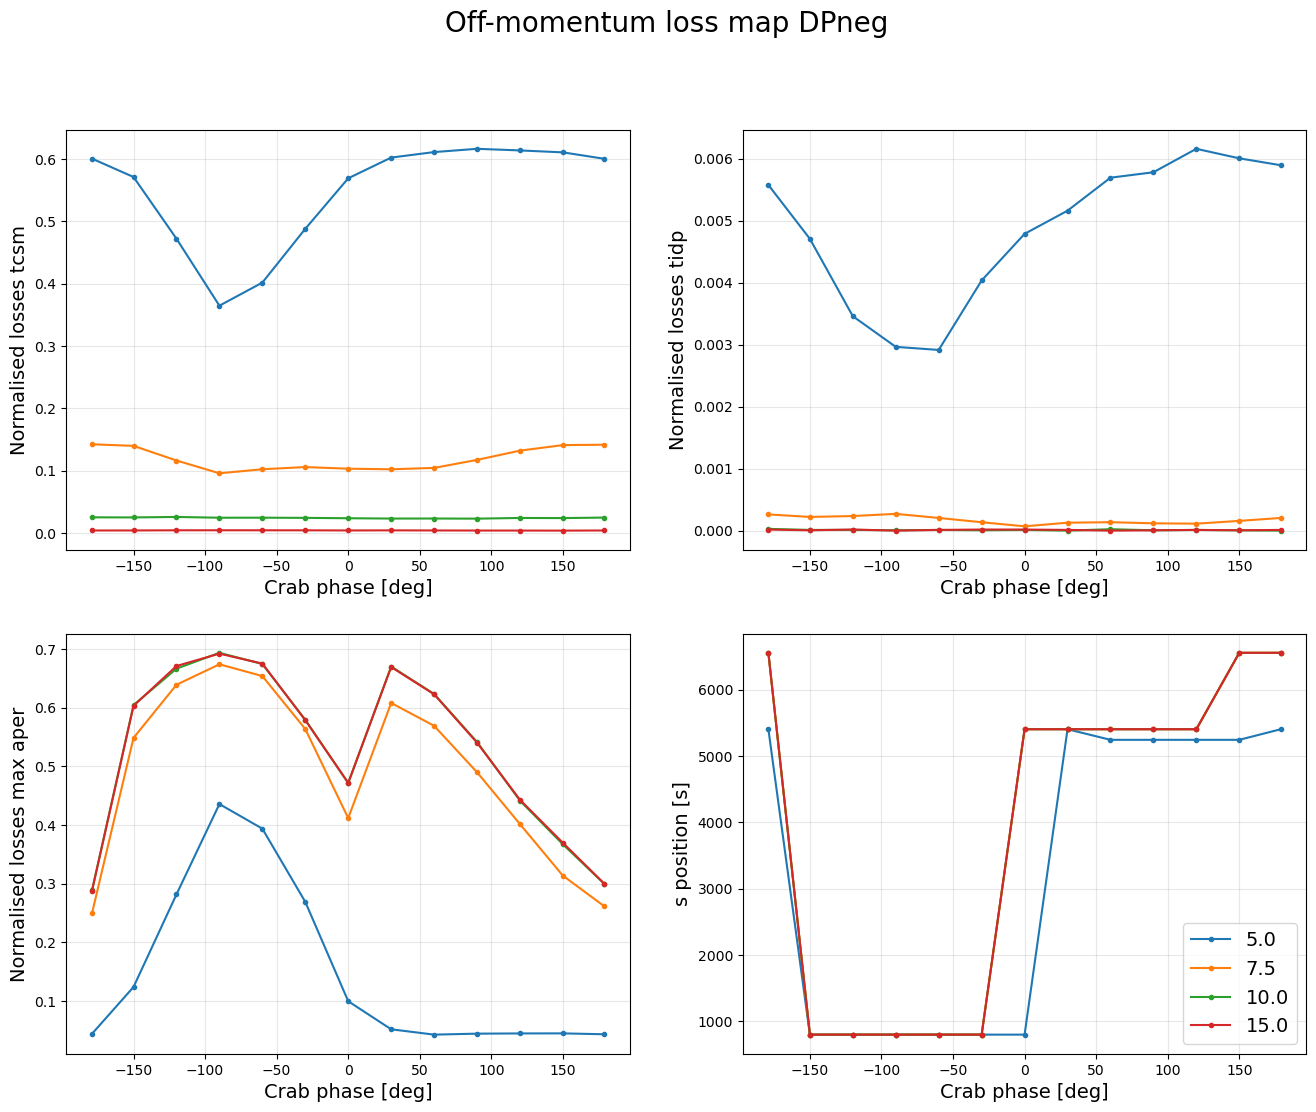

In [113]:
plt.close('all')
fig, ax = plt.subplots(2, 2, figsize=(16,12))

gaps = ['5.0', '7.5', '10.0', '15.0']

for gap in gaps:
    loc = dico_losses_summary['H']['wo']['off_momentum']['DPneg'][gap]
    ax[0,0].plot(loc['phase'], loc['tcsm'], marker='.', label=gap)
    ax[0,1].plot(loc['phase'], loc['tidp'], marker='.', label=gap)
    ax[1,0].plot(loc['phase'], loc['aper'], marker='.', label=gap)
    ax[1,1].plot(loc['phase'], loc['aper_s'], marker='.', label=gap)

ax[0,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,0].set_ylabel('Normalised losses tcsm', fontsize=14)
ax[0,0].grid(alpha=0.3)
ax[0,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[0,1].set_ylabel('Normalised losses tidp', fontsize=14)
ax[0,1].grid(alpha=0.3)
ax[1,0].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,0].set_ylabel('Normalised losses max aper', fontsize=14)
ax[1,0].grid(alpha=0.3)
ax[1,1].set_xlabel('Crab phase [deg]', fontsize=14)
ax[1,1].set_ylabel('s position [s]', fontsize=14)
ax[1,1].grid(alpha=0.3)
ax[1,1].legend(fontsize=14)

fig.suptitle('Off-momentum loss map DPneg', fontsize=20)
plt.show()